# Partie 1 · Validation du cluster
Dans le Master UI, attendre que les deux Workers soient ALIVE. Exécuter les cellules dans l’ordre. Garder cette session ouverte pendant les captures des onglets Jobs et Executors.

In [4]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .master("spark://spark-master:7077")
    .appName("Bilal-Partie1-Validation")
    .getOrCreate()
)
sc = spark.sparkContext
sc.setLogLevel("WARN")
assert sc.master == "spark://spark-master:7077", sc.master

## Exécuter un calcul distribué
Les quatre partitions donnent plusieurs tâches à planifier. L’action sum() attend leur résultat. Les quatre valeurs demandées dans le sujet sont affichées après ce premier job.

In [5]:
total = sc.parallelize(range(1, 1001), 4).sum()
assert total == 500500, total
print("Somme de 1 à 1000 =", total)
print("Version Spark      =", spark.version)
print("Master             =", sc.master)
print("appName            =", sc.appName)
print("defaultParallelism =", sc.defaultParallelism)

Somme de 1 à 1000 = 500500
Version Spark      = 3.5.8
Master             = spark://spark-master:7077
appName            = Bilal-Partie1-Validation
defaultParallelism = 2


## Écrire et relire depuis MinIO
Le mode overwrite remplace uniquement le petit jeu de validation de ce notebook, dans un préfixe distinct des données métier.

In [6]:
from pyspark.sql import functions as F

path = "s3a://lake/validation/partie1/nombres"
spark.range(1, 101, numPartitions=2).write.mode("overwrite").parquet(path)
result = spark.read.parquet(path).agg(
    F.count("*").alias("lignes"),
    F.sum("id").alias("somme"),
).first()
assert (result.lignes, result.somme) == (100, 5050), result
print(f"{path} → {result.lignes} lignes, somme = {result.somme}")

s3a://lake/validation/partie1/nombres → 100 lignes, somme = 5050


## Captures
Enregistrer le notebook. Capturer les deux Workers dans le Master (8080), les valeurs de la session, les executors dans l’application (4040) et le bucket dans MinIO (9001). Après les captures, exécuter spark.stop() dans une nouvelle cellule pour libérer les deux cœurs.

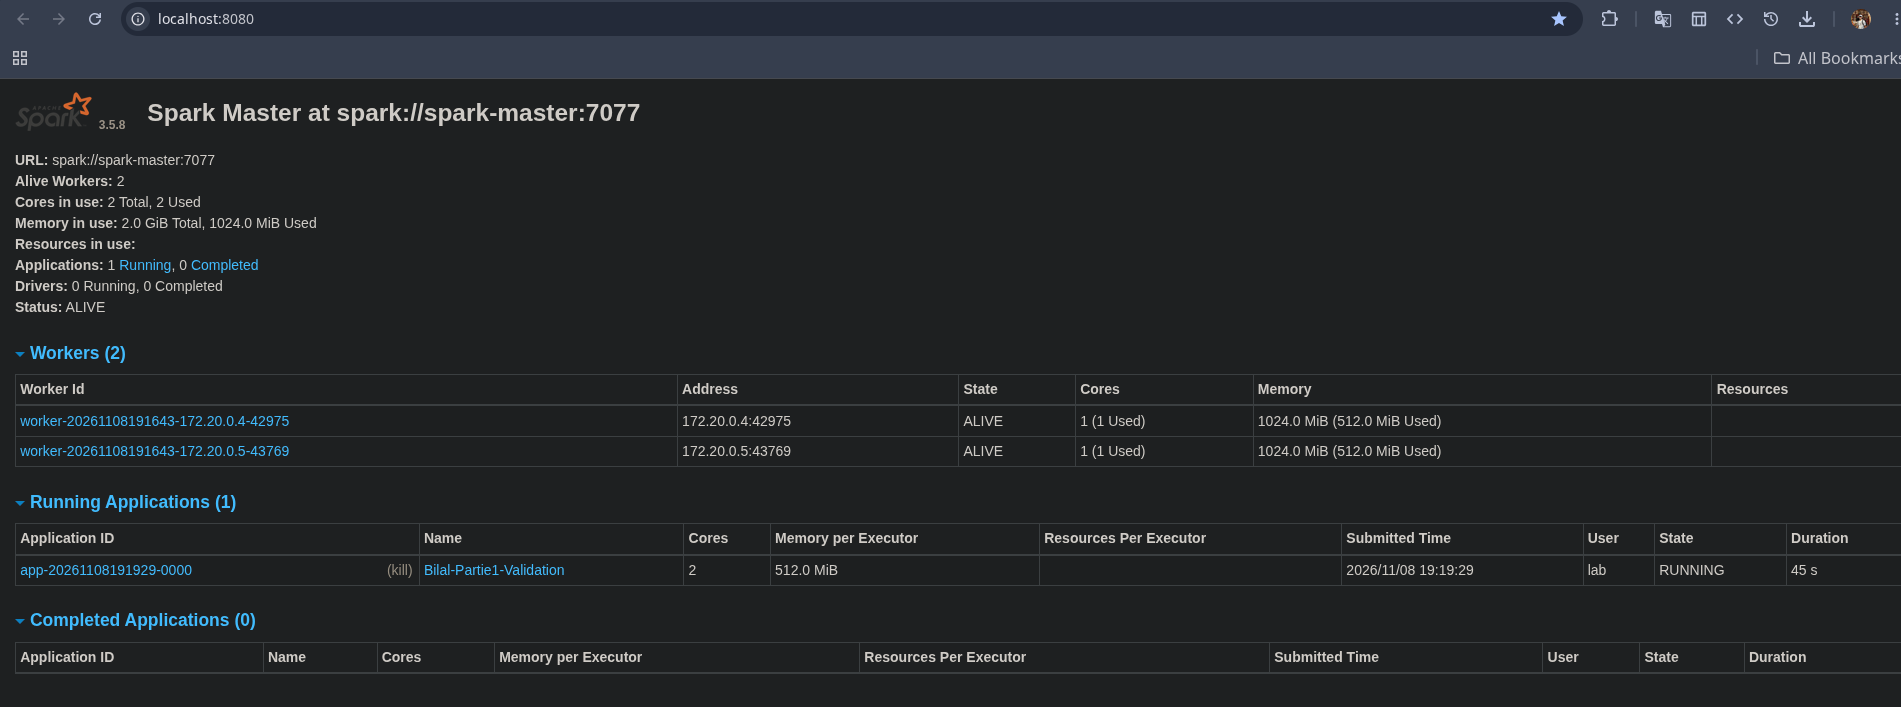

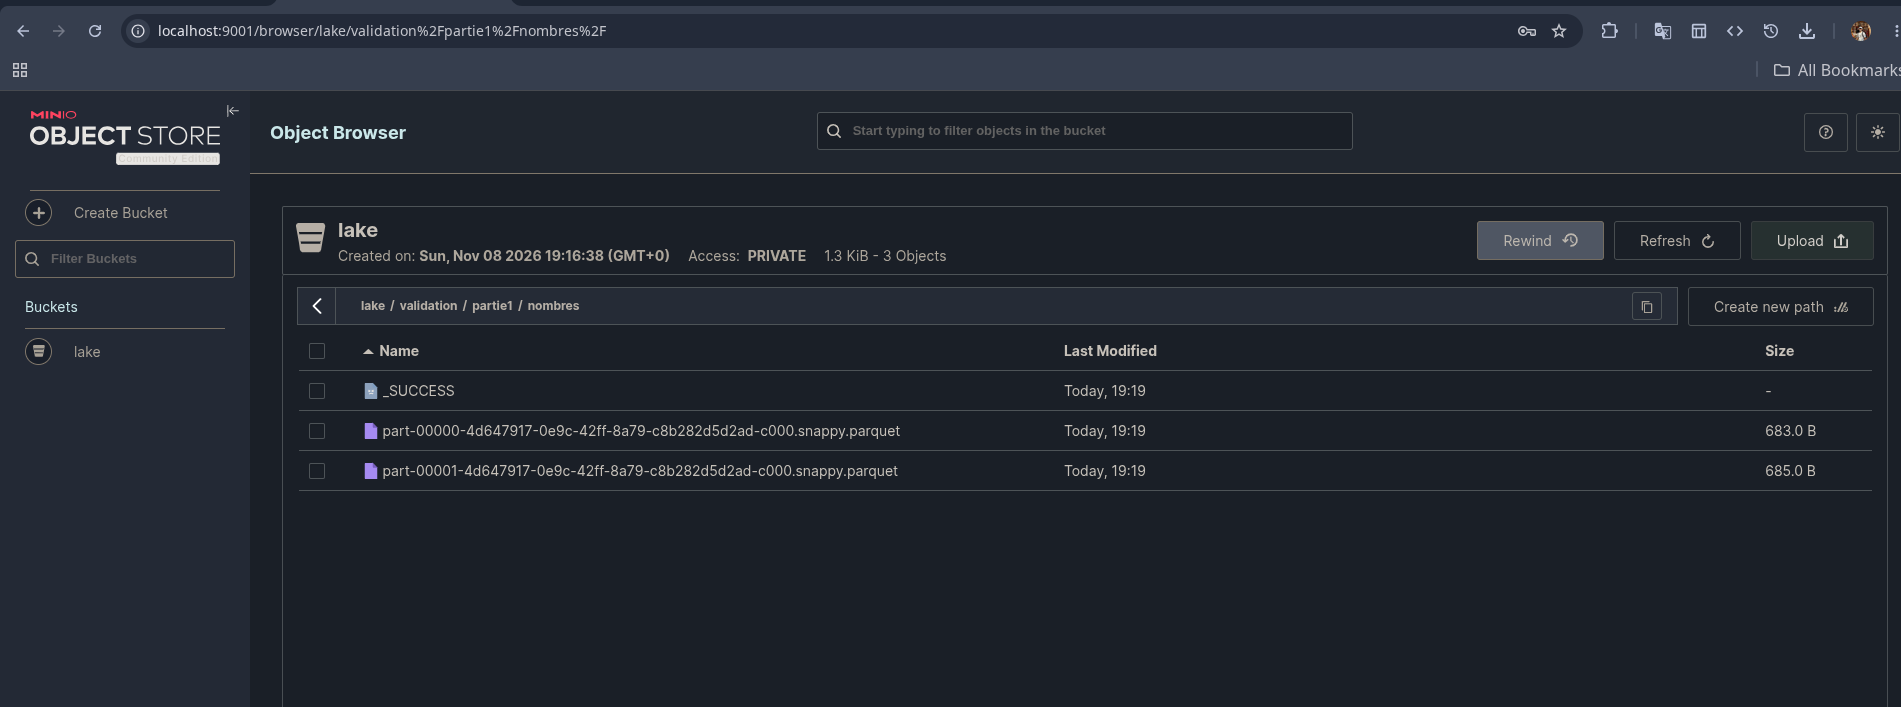

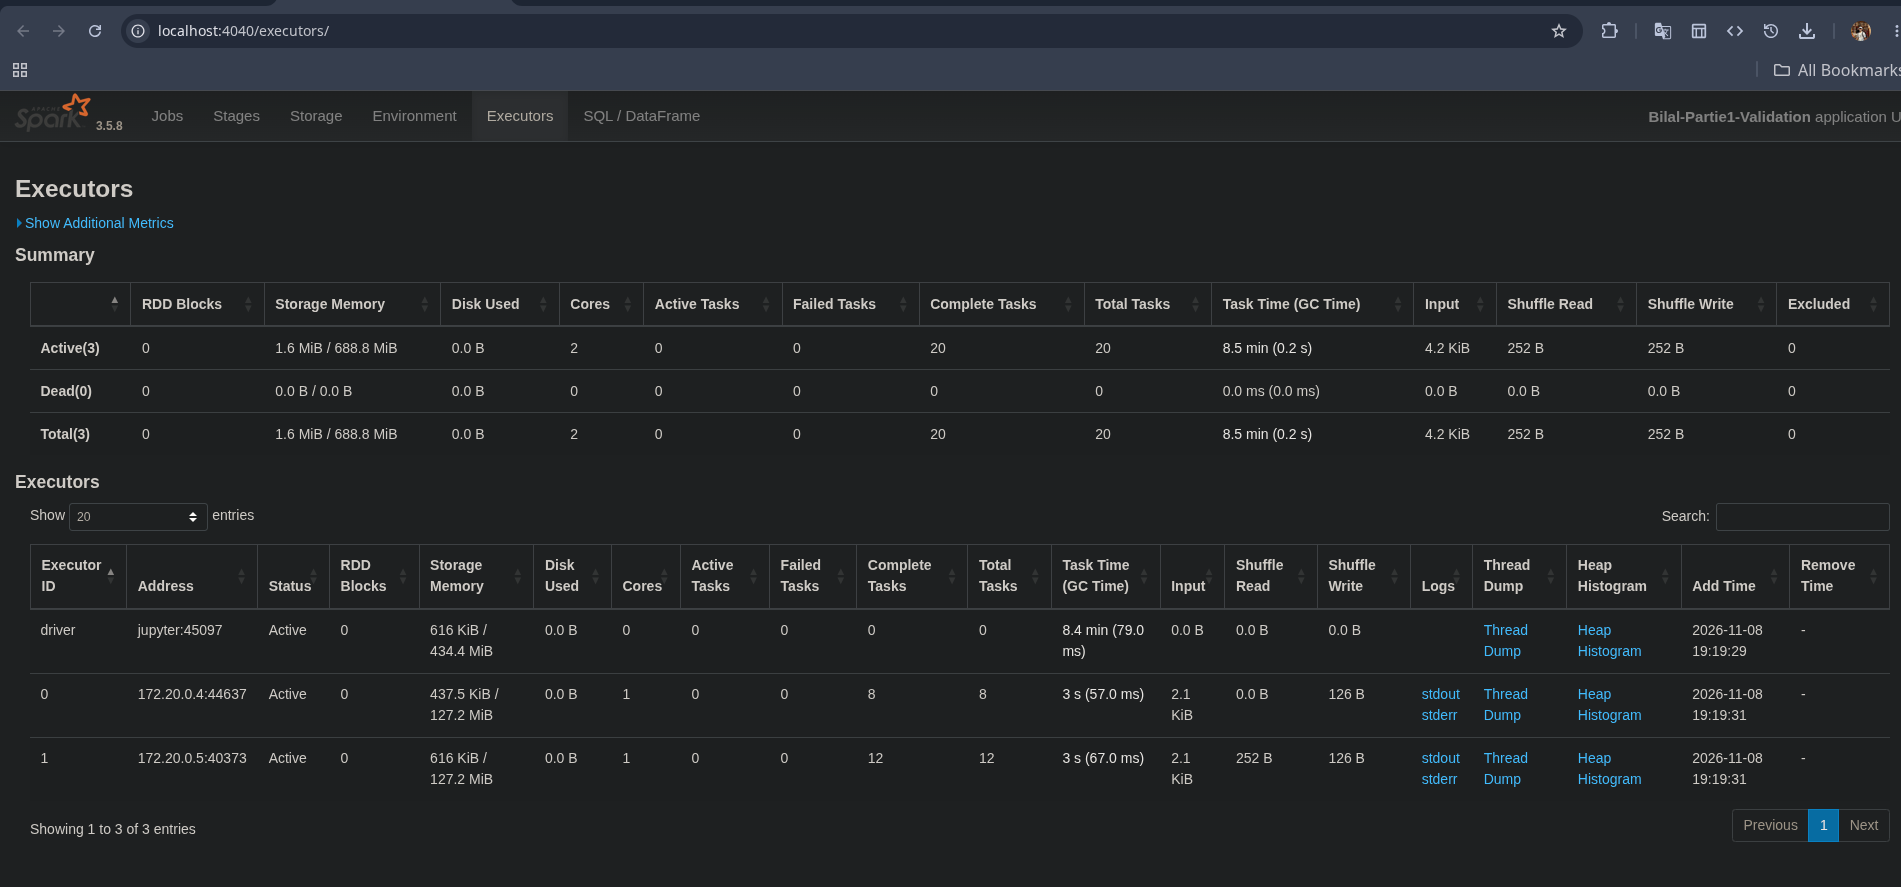

In [7]:
spark.stop()